### 지금까지 배웠던 개념
- 상태(State): 지금 어디에 있고, 어떤 상황인지. 예) 미로의 2행 3열
- 행동(Action): 에이전트가 할 수 있는 선택. 예) 위/아래/왼쪽/오른쪽
- 보상(Reward): 행동 후 환경이 주는 숫자 피드백. 예) 출구 + 10, 충돌 - 1
- 정책(Policy): 상태를 보고 어떤 행동을 할지 정하는 규칙.
- 가치(Value): 당장의 보상뿐 아니라 앞으로 얻을 보상까지 고려한 예상 점수.
- 에피소드(Episode): 시작부터 종료까지 한 번의 시도.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


# **1. TD Learning**

- 어떤 길이 좋은지 판단하려면 원래는 끝까지 가서 받은 보상을 알아야 함
- 미로가 길거나 게임이 오래 지속되면 기다리는 동안 배울 수 없음
- TD는 한 칸 움직인 직후 예상치를 고침

```
1. A 위치의 미래 점수를 지금 3점으로 예상
2. A에서 B로 이동(즉시 1점을 받음)
3. B에서 앞으로 얻을 점수는 5점이라고 예상
4. 미래 점수를 90%만 반영한다면 새로운 목표는 1 + 0.9*5 = 5.5점
5. 현재 예상 3점과 새 목표 5.5점의 차이는 +2.5점. 한 번의 경험만 믿고 3점을 곧바로 5.5점으로 바꾸면 불안정할 수 있으므로 차의 10%인 0.25점만 반영해 3.25점으로 수정
```

$
delta = r + \gamma V(s') - V(s)
$

- V(s): 이동 전 상태 A에 대해 원래 예상했던 점수 예) 3
- r: 실제 이동 직후 받은 보상 예) 1
- V(s'): 이동 후 상태 B에서 앞으로 받을 것으로 예상하는 점수 예) 5
- $\gamma$: 미래 점수를 현재에 얼마나 반영할지 정하는 할인율 예) 0.9
- $delta$: 예상과 새 목표의 차이 예) TD 오차 > 2.5

> 5.5점은 미래의 실제 정답이 아니라 현재의 추정값을 사용해 만든 임시 학습 목표. 이를 부트스트래핑(bootstrapping)이라고 부름

In [2]:
v_a, v_b = 3.0, 5.0
# alpha: 학습률. 새로운 경험을 얼마나 크게 반영할지
reward, gamma, alpha = 1.0, 0.9, 0.1
target = reward + gamma * v_b
td_error = target - v_a
new_v_a = v_a + alpha * td_error
print(f'목표={target:.2f}, 오차={td_error:.2f}, 수정된 V(A)={new_v_a:.2f}')
assert abs(new_v_a - 3.25) < 1e-9

목표=5.50, 오차=2.50, 수정된 V(A)=3.25


1. Monte Carlo
- 업데이트: 에피소드가 끝난 뒤
- 목표: 실제 관찰된 누적 보상
- 장점: 목표에 부트스트래핑 추정값을 사용하지 않음
- 주의점: 종료까지 기다려야 하고, 결과 변동이 클 수 있음

2. TD
- 업데이트: 매 전이 직후
- 목표: 보상 + 다음 상태의 추정 가치
- 장점: 긴 에피소드에도 빠르게 갱신
- 주의점: 추정값을 다시 사용해 편향이 생길 수 있음

> 둘 중 하나가 항상 우월한 것은 아님. 환경과 학습 조건에 따라 선택

### Monte Carlo(MC)와 TD Learning의 학습 과정 및 성능 비교
1. 0번부터 6번까지 총 7개의 상태로 구성된 1차원 환경을 구현
- 로봇은 항상 3번 상태에서 시작
- 매번 왼쪽 또는 오른쪽으로 50% 확률로 이동
- 0번에 도착하면 보상 0점을 받고 종료
- 6번에 도착하면 보상 +1점을 받고 종료
- 그 외의 이동에서는 보상이 0점

2. Monte Carlo 학습 구현
- 에피소드가 종료된 후 학습
- 실제로 얻은 누적 보상을 계산
- 학습률을 적용하여 상태 가치를 업데이트

3. TD Learning 구현
- 다음 상태의 추정 가치를 이용
- TD Target과 TD Error를 계산
- 학습률을 적용하여 상태 가치를 업데이트

4. 학습 결과 비교
- 에피소드 수: 300
- 학습률: 0.05
- 할인률: 1.0
- 모든 상태 가치의 초기값: 0

5. 학습이 완료되면 아래 내용을 출력
- 각 상태의 실제 가치
- MC가 학습한 상태 가치
- TD가 학습한 상태 가치
- 에피소드별 MC와 TD의 RMSE 변화 그래프

6. 아래 질문에 답하세요.
- MC와 TD Learning은 상태 가치를 업데이트하는 시점과 방법에서 어떤 차이가 있나요?
    - MC: 에피소드가 완전히 종료된 후 실제로 얻은 누적 보상(Return)을 이용하여 상태 가치를 업데이트
    - TD: 에피스드가 종료될 때까지 기다리지 않고, 한 번의 행동으로 얻은 보상과 다음 상태의 예상 가치를 이용하여 현재 상태의 가치를 업데이트할 수 있음
- RMSE가 작다는 것은 무엇을 의미하나요?
    - 강화학습에서는 알고리즘이 학습한 상태 가치와 실제 상태 가치가 얼마나 차이 나는지 확인할 때 사용
    - 예) MC가 예측한 가치: 오차 0.02, TD가 예측한 가치: 오차 0.10 > MC 예측이 실제 가치에 더 가까움
    - RMSE가 작을수록 알고리즘이 학습한 상태 가치가 실제 정답에 가깝다는 의미 > RMSE가 0이면 비교한 모든 상태의 예측 가치가 실제 가치와 정확히 일치한다는 뜻
- 실습 결과에서 MC와 TD 중 어느 알고리즘이 더 빠르게 참값에 가까워졌나요? 그 이유는?
    - 일반적으로 Random 실습에서는 TD Learning보다 MC가 더 빠르게 참값에 가까워지는 경향이 있음
    - TD Learning은 매 이동에서 얻은 보상과 다음 상태의 추정 가치를 활용하여 학습 > 에피소드의 최종 결과만을 학습 목표로 사용하는 MC와 달리 이미 학습한 다른 상태의 가치 정보를 현태 상태의 학습에 활용
    - MC는 에피소드가 종료된 후 실제 누적 보상을 이용 > Random 환경에서는 같은 상태에서 출발하더라도 0번 또는 6번에 도착할 수 있기 때문에, 에피소드마다 누적 보상이 0 또는 1로 달라짐 > MC는 학습 목표의 변동성이 상대적으로 클 수 있음

In [3]:
def random_walk_episode(rng):
    state=3
    transitions=[]
    while state not in (0, 6):
        action = rng.choice([-1, 1])
        nxt = state + action
        done = nxt in (0, 6)
        reward = 1.0 if nxt == 6 else 0.0
        transitions.append((state, reward, nxt, done))
        state = nxt
    return transitions

In [4]:
# alpha: 학습률. 새로운 목표가 나타났다고 기존 값을 한 번에 바꾸지 않는다는 뜻. 예) 새로운 정보와 기존 추정치의 차이를 0.05 반영
def compare_mc_td(episodes=300, alpha=0.05):
    rng = np.random.default_rng(SEED)
    mc = np.zeros(7)
    td = np.zeros(7)
    mc_errors, td_errors = [], []
    truth = np.arange(1, 6) / 6
    for _ in range(episodes):
        path = random_walk_episode(rng)
        for s, r, nxt, done in path:
            # td[s]: 현재 상태의 기존 예상 가치
            # r + (0 if done else td[nxt]): 지금 받은 보상 + 다음 상태의 예상 가치
            # r + (0 if done else td[nxt]) - td[s]: 예상이 얼마나 틀렸는지 나타내는 TD 오차
            td[s] += alpha * (r + (0 if done else td[nxt]) - td[s])
        G = 0.0 # 현재 시점부터 에피소드 종료까지 얻은 누적 보상
        """
        역순 처리       현재 보상       누적 보상
        5 > 6            1               1
        4 > 5            0               1
        3 > 4            0               1
        """
        for s, r, nxt, done in reversed(path):
            G = r + G
            mc[s] += alpha * (G - mc[s])
        mc_errors.append(np.sqrt(np.mean((mc[1:6]-truth)**2)))
        td_errors.append(np.sqrt(np.mean((td[1:6]-truth)**2)))
    return mc, td, mc_errors, td_errors

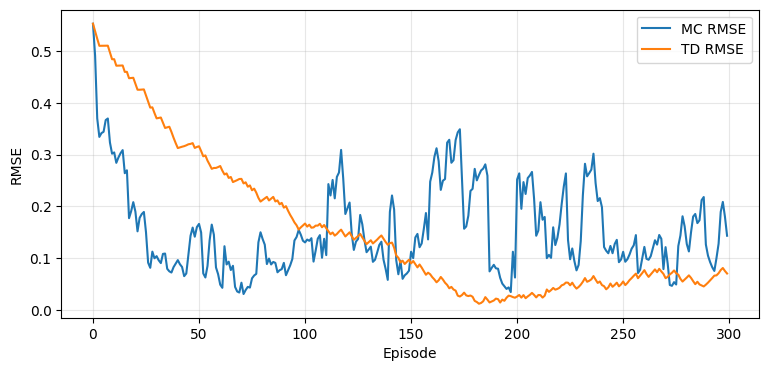

참값: [0.167 0.333 0.5   0.667 0.833]
MC  : [0.181 0.491 0.715 0.828 0.907]
TD  : [0.237 0.412 0.542 0.76  0.891]


In [5]:
mc_v, td_v, mc_err, td_err = compare_mc_td()
plt.figure(figsize=(9, 4))
plt.plot(mc_err, label='MC RMSE'); plt.plot(td_err, label='TD RMSE')
plt.xlabel('Episode'); plt.ylabel('RMSE'); plt.legend(); plt.grid(alpha=.3); plt.show()
print('참값:', np.round(np.arange(1,6)/6, 3))
print('MC  :', np.round(mc_v[1:6], 3))
print('TD  :', np.round(td_v[1:6], 3))

### Grid 환경 구현 및 TD Learning을 이용한 상태 가치 학습

1. 5 * 5 크기의 격자 환경을 구현
- 시작 위치 (0, 0)
- 목표 위치 (4, 4)
- 장애물 위치: (1, 1), (1, 2), (3, 3)
- 행동: 상/하/좌/우
- 목표 도착 보상: +10
- 일반 이동 보상: -0.1
- 에피소드당 최대 이동 횟수: 100
- 로봇은 격자 범위를 벗어나거나 장애물로 이동하려고 하면 현재 위치에 머무름
- 단, 이동하지 못하더라도 이동 횟수는 증가하고 보상 -0.1이 적용
- 목표에 도착하면 에피소드가 종료되며, 최대 이동 횟수에 도달하면 해당 에프소드를 중단

2. 학습 조건
- 에피소드 수: 2000
- 학습률: 0.08
- 할인율: 0.95
- 행동 선택: 상/하/좌/우 무작위 선택
- 상태 가치 초기값: 모두 0

3. 시각화
- 학습된 5 * 5 상태 가치 배열 V
- 각 위치의 상태 가치를 표현한 Heatmap

- TD Learning에서 다음 상태 가치를 사용하는 이유?
    - 현재 상태에서 앞으로 얻을 보상을 아직 정확히 알 수 없기 때문에, 다음 상태에 대해 지금까지 학습한 예상 가치를 이용하여 현재 상태의 가치를 추정하기 위함
- 목표 지점에 가까운 위치와 먼 위치의 상태 가치에는 어떤 차이가 나타나는지. 그 이유는 무엇인지?
    - 일반적으로 목표 지점에 가까운 위치는 먼 위치보다 상태 가지가 높게 나타나는 경향이 있음
- 장애물 주변의 상태 가치는 다른 위치와 어떤 차이가 있는지?
    - 장애물 주변의 상태 가치는 장애물이 없는 위치와 다르게 나타날 수 있으며, 목표로 이동하기 어려운 위치에서는 상대적으로 낮은 상태 가치가 나타나는 경향이 있음
    - 장애물 때문에 이동할 수 있는 경로가 제한되고, 목표까지 우회해야 하거나 제자리에서 시간을 소비할 가능성이 높아지기 때문

In [ ]:
class GridWorld:
    ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    def __init__(self, size=5, walls=((1, 1), (1, 2), (3, 3)), max_steps=100):
        self.size = size
        self.walls = set(walls)
        self.goal = (size-1, size-1)
        self.start = (0, 0)
        self.max_steps = max_steps
        assert self.goal not in self.walls and self.start not in self.walls
        self.reset()

    def reset(self):
        """(0, 0)을 반환"""
        self.pos = self.start
        self.steps = 0
        return self.pos

    def step(self, action: int):
        dr, dc = self.ACTIONS[action]
        r, c = self.pos
        candidate = (r + dr, c + dc)
        if (0 <= candidate[0] < self.size and 0 <= candidate[1] < self.size and candidate not in self.walls):
            self.pos = candidate
        self.steps += 1
        terminated = self.pos == self.goal
        truncated = self.steps >= self.max_steps and not terminated
        reward = 10.0 if terminated else -0.1
        return self.pos, reward, terminated, truncated

In [7]:
env = GridWorld()
V = np.zeros((env.size, env.size))
alpha, gamma = 0.08, 0.95
rng = np.random.default_rng(SEED)
for episode in range(2000):
    state = env.reset()
    while True:
        action = int(rng.integers(4))
        nxt, reward, terminated, truncated = env.step(action)
        bootstrap = 0 if terminated else V[nxt]
        V[state] += alpha*(reward + gamma * bootstrap - V[state])
        state=nxt
        if terminated or truncated:
            break

랜덤 정책 아래 추정된 V(s):
[[-1.23 -1.26 -1.16 -0.82 -0.19]
 [-1.02  0.    0.   -0.27  0.56]
 [-0.84 -0.45 -0.06  0.31  1.9 ]
 [-0.5  -0.21  0.74  0.    5.2 ]
 [-0.33  0.69  2.36  5.57  0.  ]]


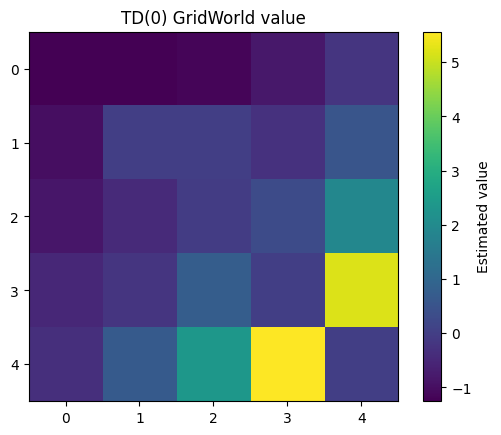

In [8]:
print('랜덤 정책 아래 추정된 V(s):')
print(np.round(V, 2))
plt.imshow(V, cmap='viridis')
plt.colorbar(label='Estimated value')
plt.title('TD(0) GridWorld value')
plt.show()

# **2. Q-Learning**
최적 행동 가치 Q에 가까워지도록 학습하여, 각 상태에서 Q가 큰 행동을 선택하는 것을 목표로 함

```
로봇이 갈림길 A에 있음
V(A) = 5 : A에 있을 때 앞으로 얼마나 좋은가?를 뜻
현재 왼쪽과 오른쪽 중 뭇엇을 선택할지는 알려주지 못함

Q(A, 왼쪽)=2, Q(A, 오른쪽)=8 : 오른쪽을 고를 수 있음(Q는 상태와 행동을 묶어 평가한 점수)
```

V(s): 이 상태에서 정책을 따라가면 앞으로 받을 예상 보상
Q(s, a): 이 상태에서 특정 행동 a를 먼저 선택하고 이후 정책을 따르면 받을 예상 보상

> 정책에 따라 V와 Q의 값도 달라질 수 있음. Q-Learning은 최적 행동 가치 Q에 가까워지도록 학습하여, 각 상태에서 Q가 큰 행동을 선택하는 것을 목표로 함

### Q-Learning의 계산 과정
1. 지금 (상태, 행동)의 기존 Q점수를 확인
2. 실제 행동을 해 보상을 받음
3. 다음 상태에서 가장 점수가 높은 행동의 Q값을 찾음
4. 지금 받은 보상 + 할인된 다음 상태 최고 점수를 새 목표로 삼음
5. 기존 점수와 목표의 차이를 학습률만큼 반영

In [9]:
q_old=0.0; reward=10.0; alpha=0.1; gamma=0.9
max_next_q=0.0
q_new=q_old+alpha*(reward+gamma*max_next_q-q_old)
print('새 Q(3, 오른쪽):', q_new)

새 Q(3, 오른쪽): 1.0


```
S . . . G 의 5개 위치, 행동은 왼쪽(0)/오른쪽(1)
목표 도착 +10, 그외 -1
ε-greedy는 ε 확률로 탐험, 나머지는 현재 최선 행동을 선택
동점에서는 랜덤 선택하여 초기 왼쪽/오른쪽 편향을 줄임 
```

In [10]:
def train_line_q(episodes=400, epsilon=0.2, alpha=0.3, gamma=0.9):
    rng = np.random.default_rng(SEED)
    Q = np.zeros((5, 2)) # 행=상태 0~4, 열=행동 0~1
    """
    상태            왼쪽Q       오른쪽Q
    0               0           0
    1               0           0
    2               0           0
    3               0           0
    4               0           0
    """
    rewards = []
    for ep in range(episodes):
        state=0
        total=0
        for step in range(30):
            # 탐험을 수행
            if rng.random() < epsilon:
                action = int(rng.integers(2))
            else:
                # 탐험을 하지 않는 경우 현재 Q값이 가장 높은 행동을 선택
                # Q[2] = [2.0, 5.0] 왼쪽 행동가치는 2.0, 오른쪽 행동 가치는 5.0
                # 각 행동의 Q값이 최댓값과 같은지 확인
                # flatnonzero: 조건이 참인 위치의 인덱스를 반환
                best = np.flatnonzero(Q[state] == Q[state].max())
                action = int(rng.choice(best))
            nxt = int(np.clip(state + (-1 if action == 0 else 1), 0, 4))
            done = nxt == 4
            reward = 10 if done else -1
            target = reward + (0 if done else gamma * np.max(Q[nxt]))
            # 즉시 보상: 지금 행동해서 받은 보상
            # 다음 상태에서 가장 좋은 행동의 가치: 다음 상태에 도착한 후 선택할 수 있는 행동 중 Q값이 가장 높은 행동의 가치
            # TD Target: 즉시 보상과 다음 상태에서 얻을 수 있는 최대 예상 가치를 합한 값
            # TD / Q-Learning 차이는? TD 상태 가치 평가는 정해진 정책 아래의 상태 가치를 학습하는 반면, Q-Learning은 다음 상태에서 가장 좋은 행동을 선택한다고 가정하여 행동 가치를 학습
            Q[state, action] += alpha * (target - Q[state, action])
            total += reward
            state = nxt
            if done: break
        rewards.append(total)
    return Q, np.asarray(rewards)

Q 테이블 (왼쪽, 오른쪽):
 [[ 3.12  4.58]
 [ 3.12  6.2 ]
 [ 4.58  8.  ]
 [ 6.2  10.  ]
 [ 0.    0.  ]]
학습된 정책: ['→', '→', '→', '→']


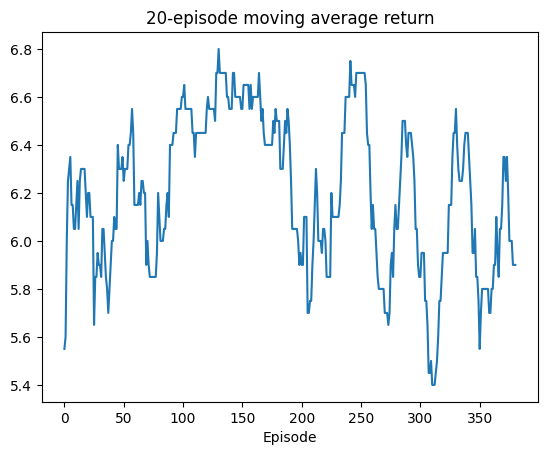

In [11]:
Q, line_returns=train_line_q()
print('Q 테이블 (왼쪽, 오른쪽):\n',np.round(Q,2))
print('학습된 정책:', ['←' if a==0 else '→' for a in Q[:4].argmax(axis=1)])
# 연속된 20개 에피소드의 평균을 계산. mode='valid': 20개의 데이터가 모두 존재하는 구간만 계산
plt.plot(np.convolve(line_returns,np.ones(20)/20,mode='valid'))
plt.title('20-episode moving average return'); plt.xlabel('Episode');plt.show()

## 3. SARSA

- 다음에 실제로 선택한 행동을 사용
- 위험한 절벽 근처에서 ε-greedy 탐험이 계속되면 SARSA는 탐험 위험을 반영한 경로를 학습할 수 있음(환경과 설정에 따라 결과는 달라짐)
- State > action > reward > next State > next Action 의 머리글자

```
절벽 옆을 걷는 로봇이 있음
최단 경로는 절벽 가까이에 있지만, 탐험 중 엉뚱한 행동을 하면 떨어질 수 있음
```

- Q-Learning: `r + γ max Q(s′,a′)` 다음 위치에서 가장 좋은 행동을 했다고 가정한 값으로 현재 Q값을 고침
- SARSA: `r + γ Q(s′,a′)` 다음 위치에서 실제로 선택한 행동을 값으로 고침

예를 들어 보상 r=1, 할인율 γ=0.9, 다음 위치의 최고 Q값이 10인데 실제로 선택한 행동의 Q값은 2라면, Q-Learning의 목표값은 10, SARSA 목표값은 2.8.

> SARSA는 현재 행동 선택 정책을 따르는 온폴리시, Q-Learning은 다음 행동의 최대값을 사용하는 오프폴리시. SARSA가 언제나 안전하다는 뜻은 아니며 탐험 정책과 환경에 따라 달라짐

In [12]:
def train_line_sarsa(episodes=400, epsilon=0.2, alpha=0.3, gamma=0.9):
    rng = np.random.default_rng(SEED)
    Q = np.zeros((5, 2)) # 행=상태 0~4, 열=행동 0~1
    """
    상태            왼쪽Q       오른쪽Q
    0               0           0
    1               0           0
    2               0           0
    3               0           0
    4               0           0
    """
    rewards = []
    for ep in range(episodes):
        state=0
        total=0
        for step in range(30):
            # 탐험을 수행
            if rng.random() < epsilon:
                action = int(rng.integers(2))
            else:
                # 탐험을 하지 않는 경우 현재 Q값이 가장 높은 행동을 선택
                # Q[2] = [2.0, 5.0] 왼쪽 행동가치는 2.0, 오른쪽 행동 가치는 5.0
                # 각 행동의 Q값이 최댓값과 같은지 확인
                # flatnonzero: 조건이 참인 위치의 인덱스를 반환
                best = np.flatnonzero(Q[state] == Q[state].max())
                action = int(rng.choice(best))
            nxt = int(np.clip(state + (-1 if action == 0 else 1), 0, 4))
            done = nxt == 4
            reward = 10 if done else -1
            target = reward + (0 if done else gamma * Q[nxt][action])
            # 즉시 보상: 지금 행동해서 받은 보상
            # 다음 상태에서 가장 좋은 행동의 가치: 다음 상태에 도착한 후 선택할 수 있는 행동 중 Q값이 가장 높은 행동의 가치
            # TD Target: 즉시 보상과 다음 상태에서 얻을 수 있는 최대 예상 가치를 합한 값
            # TD / Q-Learning 차이는? TD 상태 가치 평가는 정해진 정책 아래의 상태 가치를 학습하는 반면, Q-Learning은 다음 상태에서 가장 좋은 행동을 선택한다고 가정하여 행동 가치를 학습
            Q[state, action] += alpha * (target - Q[state, action])
            total += reward
            state = nxt
            if done: break
        rewards.append(total)
    return Q, np.asarray(rewards)

In [ ]:
def train_grid_sarsa(episodes=3000):
    rng = np.random.default_rng(SEED)
    env = GridWorld()

    Q = np.zeros((env.size, env.size, 4))
    history = []

    def choose_action(state, epsilon):
        if rng.random() < epsilon:
            # 1 ~ 4 랜덤
            return int(rng.integers(4))
        else:
            # 현재 위치 (r, c) 에서 [4] 크기의 행동 가치 가져와주기
            values = Q[state]
            # 행동 가치중에서 가장 높은 가치의 번호 가져오기
            best = np.flatnonzero(values == values.max())
            # 가장 높은 위치의 인덱스중에서 아무거나 가져오기 (같은 경우에 2개 반환)
            return int(rng.choice(best))

    for ep in range(episodes):
        # 0, 0 에서 시작
        state = env.reset()
        total = 0
        # 에피소드가 지날수록 엡실론 확률 낮춰주기 -> 0.05까지만 줄여주기
        epsilon = max(0.05, 0.8 * (0.997 ** ep))

        # 다음으로 할 행동 번호 (0 ~ 3) 가져와주기
        action = choose_action(state, epsilon)

        while True:
            # 이동 한번 하기
            # (r, c), 보상(도착 시 10, 아니면 -0.1), 종료 플래그  
            nxt, reward, terminated, truncated = env.step(action)
            if terminated:
                # 종료시점에는 다음 행동 가치가 없기때문에 보상을 target로 설정하기
                target = reward
                next_action = None
            else:
                # 다음 행동 미리 결정해놓기
                next_action = choose_action(nxt, epsilon)
                # Q[nxt][next_action]: 다음 상태에서 실제로 선택한 행동의 Q값
                # 타겟 업데이트 수식 적용 -> 보상 + 다음 행동 가치 가져와주기
                target = reward + 0.95 * Q[nxt][next_action]

            # 0.15: 학습률
            # Q값이 4, SARSA 목표값이 6.4
            # 4 + 0.15(6.4 - 4) = 4.36
            # 현재 행동 업데이트해주기
            Q[state][action] += 0.15 * (target - Q[state][action])
            total += reward

            if terminated or truncated:
                break

            # 앞에서 선택한 next_action을 다음 반복의 action으로 사용
            # 다음 반복에서 행동을 새롭게 선택하면, Q값 업데이트에 사용한 행동과 실제로 실행한 행동이 달라질 수 있음. > 그러면 SARSA 방식이 아님
            state = nxt
            action = next_action

        history.append(total)

    return Q, np.array(history)

↓ ← → ↓ ↓
↓ ██ ██ ↓ ↓
→ ↓ ↓ → ↓
→ → ↓ ██ ↓
→ → → → GO


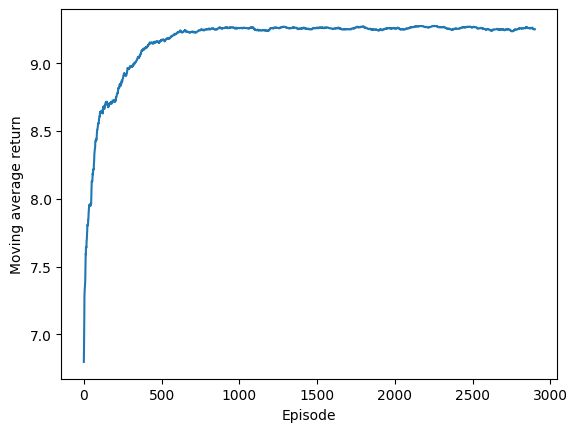

In [14]:
Qsarsa, sarsa_returns = train_grid_sarsa()
arrow = np.array(['↑', '↓', '←', '→'])

for r in range(5):
    print(' '.join('██' if (r, c) in GridWorld().walls else 'GO' if (r, c) == (4, 4)
                   else arrow[np.argmax(Qsarsa[r, c])] for c in range(5)))

plt.plot(np.convolve(sarsa_returns, np.ones(100) / 100, mode='valid'))
plt.xlabel('Episode')
plt.ylabel('Moving average return')
plt.show()

In [15]:
Qsarsa

array([[[ 5.75442162,  6.12595709,  5.77151343,  4.5843222 ],
        [-0.4473376 , -0.19661508,  5.70287885,  0.43234811],
        [-0.12421855,  0.17854037,  0.05546543,  1.71756126],
        [ 0.02357934,  3.02541554, -0.30240882,  0.26678702],
        [-0.12665714,  2.34427282, -0.0924045 ,  0.03557914]],

       [[ 5.58707793,  6.66448347,  6.19108054,  6.16205855],
        [ 0.        ,  0.        ,  0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        ,  0.        ],
        [ 0.28594713,  4.36661445,  0.84699523,  1.94523934],
        [ 0.24237915,  6.48570215,  0.83809968,  1.56162359]],

       [[ 6.03672645,  6.43277282,  6.66361594,  7.14764098],
        [ 7.12378334,  7.6357324 ,  6.44942678,  7.47219653],
        [ 4.66087211,  8.18131126,  3.84056718,  4.423939  ],
        [ 1.65701156,  3.44805752,  2.65562846,  7.181904  ],
        [ 0.89408218,  8.77043166,  2.5314632 ,  4.90896146]],

       [[ 3.58434964,  3.32328372,  4.09073304,  7.56903238],
  

In [3]:
import torch.nn as nn
l = nn.Linear(10, 20)
l.weight.shape

torch.Size([20, 10])